In [ ]:
!pip install -q yfinance lxml

In [ ]:
import os, json, time, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sklearn
import yfinance as yf
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
SEED = 42
pd.set_option("display.width", 160)

versions = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
            "yfinance": yf.__version__, "scikit-learn": sklearn.__version__, "scipy": scipy.__version__}
json.dump(versions, open("outputs/package_versions.json", "w"), indent=2)
versions

{'python': '3.13.18',
 'pandas': '2.2.3',
 'numpy': '2.4.6',
 'yfinance': '0.2.66',
 'scikit-learn': '1.6.1',
 'scipy': '1.16.3'}

In [ ]:
START = "2021-01-01"
END   = "2025-01-01"
BENCHMARK = "^GSPC"

USE_CACHE = False

Task 1.1

In [ ]:
URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

if not USE_CACHE:
    tables = pd.read_html(URL, storage_options={"User-Agent": "Mozilla/5.0"})
    sp500_df = tables[0].copy()
    RETRIEVED_AT = datetime.now(timezone.utc).isoformat(timespec="seconds")
    sp500_df["Retrieved_UTC"] = RETRIEVED_AT
    sp500_df["YF_Ticker"] = sp500_df["Symbol"].str.replace(".", "-", regex=False)   # BRK.B -> BRK-B
    sp500_df.to_csv("data/sp500_tickers.csv", index=False)
else:
    sp500_df = pd.read_csv("data/sp500_tickers.csv")
    RETRIEVED_AT = sp500_df["Retrieved_UTC"].iloc[0]

tickers = sp500_df["YF_Ticker"].tolist()
info = sp500_df.set_index("YF_Ticker")[["Security", "GICS Sector", "Date added"]]
print("Ticker list retrieved (UTC):", RETRIEVED_AT)
print("Tickers extracted:", len(tickers))
sp500_df[["Symbol", "YF_Ticker", "Security", "GICS Sector", "Date added"]].head()

Ticker list retrieved (UTC): 2026-11-24T14:56:46+00:00
Tickers extracted: 503


,Symbol,YF_Ticker,Security,GICS Sector,Date added
0,MMM,MMM,3M,Industrials,1957-03-04
1,AOS,AOS,A. O. Smith,Industrials,2017-07-26
2,ABT,ABT,Abbott Laboratories,Health Care,1957-03-04
3,ABBV,ABBV,AbbVie,Health Care,2012-12-31
4,ACN,ACN,Accenture,Information Technology,2011-07-06


In [ ]:
def get_field(df, name):
    # Return one field (e.g. 'Adj Close') as a Date x Ticker table
    if name in df.columns.get_level_values(0):
        return df[name].copy()
    return pd.DataFrame(np.nan, index=df.index, columns=df.columns.get_level_values(1).unique())

FIELDS = {"close": "Close", "adj": "Adj Close", "volume": "Volume",
          "dividends": "Dividends", "splits": "Stock Splits"}

if not USE_CACHE:
    raw = yf.download(tickers, start=START, end=END, auto_adjust=False, actions=True,
                      group_by="column", threads=True, progress=True)
    data = {k: get_field(raw, v) for k, v in FIELDS.items()}

    # Retry once, one by one, for tickers that came back empty
    failed = [t for t in tickers if t not in data["adj"].columns or data["adj"][t].isna().all()]
    print("Empty on first pass:", failed)
    for t in failed:
        time.sleep(1)
        d = yf.download(t, start=START, end=END, auto_adjust=False, actions=True, progress=False)
        if isinstance(d.columns, pd.MultiIndex):
            d.columns = d.columns.get_level_values(0)
        if not d.empty:
            for k, v in FIELDS.items():
                data[k][t] = d[v] if v in d.columns else np.nan

    bench = yf.download(BENCHMARK, start=START, end=END, auto_adjust=False, progress=False)
    if isinstance(bench.columns, pd.MultiIndex):
        bench.columns = bench.columns.get_level_values(0)
    bench = bench[["Close", "Adj Close", "Volume"]]

    # Preserve the snapshot (compressed CSV, small enough for GitHub)
    for k, df in data.items():
        df.to_csv(f"data/{k}.csv.gz")
    bench.to_csv("data/gspc.csv.gz")
    json.dump({"ticker_source": URL, "ticker_retrieved_utc": RETRIEVED_AT,
               "prices_downloaded_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
               "source": "Yahoo Finance via yfinance", "start": START, "end_exclusive": END,
               "auto_adjust": False, "benchmark": BENCHMARK, **versions},
              open("data/snapshot_metadata.json", "w"), indent=2)
else:
    data = {k: pd.read_csv(f"data/{k}.csv.gz", index_col=0, parse_dates=True) for k in FIELDS}
    bench = pd.read_csv("data/gspc.csv.gz", index_col=0, parse_dates=True)

close, adj, volume, dividends, splits = (data[k] for k in ["close", "adj", "volume", "dividends", "splits"])
print("Share data:", adj.shape, "| Benchmark rows:", len(bench))
print("Benchmark first/last date:", bench.index.min().date(), "/", bench.index.max().date())
assert bench.index.max() < pd.Timestamp(END), "END must be exclusive"

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['SNDK', 'FDXF', 'VYLR', 'Q', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Empty on first pass: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERRO

Share data: (1005, 503) | Benchmark rows: 1005
Benchmark first/last date: 2021-01-04 / 2024-12-31


Task 1.2

In [ ]:
# ---- Duplicate dates
dup_share = int(adj.index.duplicated().sum())
dup_bench = int(bench.index.duplicated().sum())
print("Duplicate dates – shares:", dup_share, "| benchmark:", dup_bench)
if dup_share:
    close, adj, volume, dividends, splits = (d[~d.index.duplicated(keep="first")]
                                             for d in (close, adj, volume, dividends, splits))
if dup_bench:
    bench = bench[~bench.index.duplicated(keep="first")]

bench = bench.dropna(subset=["Adj Close"]).sort_index()
cal = bench.index                                    # reference trading calendar
extra = adj.index.difference(cal)
print("Share dates not in the benchmark calendar (dropped):", list(extra.date))

close_c, adj_c, vol_c = close.reindex(cal), adj.reindex(cal), volume.reindex(cal)
div_c, spl_c = dividends.reindex(cal).fillna(0), splits.reindex(cal).fillna(0)

FIRST_WEEK_END = cal[cal <= cal[0] + pd.offsets.Week(weekday=4)].max()   # last day of first week
MAX_GAP = 5
MAX_ZERO_VOL_SHARE = 0.05
JUMP = 0.40     # flag one-day close moves bigger than 40%

rows = []
for t in tickers:
    if t not in adj_c.columns or adj_c[t].isna().all():
        rows.append({"Ticker": t, "Reason": "No data returned"}); continue
    a, c, v = adj_c[t], close_c[t], vol_c[t]
    first, last = a.first_valid_index(), a.last_valid_index()
    inside = a.loc[first:last]
    priced = c.notna()
    split_days = spl_c.index[(spl_c[t] != 0) & (spl_c[t] != 1)]
    moves = c.pct_change(fill_method=None).abs()
    big_moves = moves.index[moves > JUMP]
    unexplained = [d.date() for d in big_moves if d not in split_days]
    r = {"Ticker": t, "First_date": first.date(), "Last_date": last.date(),
         "Missing_adj": int(a.isna().sum()), "Internal_missing": int(inside.isna().sum()),
         "Nonpositive_price": int(((a <= 0) | (c <= 0)).sum()),
         "Negative_vol": int((v < 0).sum()), "Missing_vol_on_priced_day": int((v.isna() & priced).sum()),
         "Zero_vol_days": int((v == 0).sum()),
         "Splits": len(split_days), "Dividend_days": int((div_c[t] > 0).sum()),
         "Unexplained_jumps": len(unexplained), "Jump_dates": str(unexplained[:3])}
    reasons = []
    if first > FIRST_WEEK_END or last < cal[-1]:
        reasons.append(f"Unequal history ({first.date()} to {last.date()})")
    if r["Internal_missing"] > MAX_GAP:
        reasons.append(f"{r['Internal_missing']} internal missing days")
    if r["Nonpositive_price"]:
        reasons.append("Non-positive price")
    if r["Negative_vol"] or r["Missing_vol_on_priced_day"] or r["Zero_vol_days"] > MAX_ZERO_VOL_SHARE * len(cal):
        reasons.append("Volume error")
    r["Reason"] = "; ".join(reasons) or "Retained"
    rows.append(r)

validation = pd.DataFrame(rows).set_index("Ticker").join(info)
retained = validation.index[validation["Reason"] == "Retained"].tolist()
excluded = validation[validation["Reason"] != "Retained"]
validation.to_csv("outputs/validation_log.csv")

print(f"\nExtracted {len(tickers)} | Retained {len(retained)} | Excluded {len(excluded)}")
print(excluded["Reason"].str.split(" (", regex=False).str[0].value_counts())
excluded[["Security", "GICS Sector", "Date added", "First_date", "Last_date", "Reason"]]

Duplicate dates – shares: 0 | benchmark: 0
Share dates not in the benchmark calendar (dropped): []

Extracted 503 | Retained 487 | Excluded 16
Reason
Unequal history     10
No data returned     5
Volume error         1
Name: count, dtype: int64


,Security,GICS Sector,Date added,First_date,Last_date,Reason
Ticker,,,,,,
APP,AppLovin,Communication Services,2025-09-22,2021-04-15,2024-12-31,Unequal history (2021-04-15 to 2024-12-31)
COIN,Coinbase,Financials,2025-05-19,2021-04-14,2024-12-31,Unequal history (2021-04-14 to 2024-12-31)
CEG,Constellation Energy,Utilities,2022-02-02,2022-01-19,2024-12-31,Unequal history (2022-01-19 to 2024-12-31)
EXE,Expand Energy,Energy,2025-03-24,2021-02-10,2024-12-31,Unequal history (2021-02-10 to 2024-12-31)
FDXF,FedEx Freight,Industrials,2026-06-01,NaN,NaN,No data returned
GEHC,GE HealthCare,Health Care,2023-01-04,2022-12-15,2024-12-31,Unequal history (2022-12-15 to 2024-12-31)
GEV,GE Vernova,Industrials,2024-04-02,2024-03-27,2024-12-31,Unequal history (2024-03-27 to 2024-12-31)
HONA,Honeywell Aerospace,Industrials,2026-06-29,NaN,NaN,No data returned
Q,Qnity Electronics,Information Technology,2025-11-03,NaN,NaN,No data returned


In [ ]:
# ---- Corporate actions among retained shares
ca = validation.loc[retained, ["Security", "Splits", "Dividend_days", "Unexplained_jumps", "Jump_dates"]]
print("Retained shares with a stock split in the period:", int((ca["Splits"] > 0).sum()))
print("Retained shares paying dividends:", int((ca["Dividend_days"] > 0).sum()))
print("Retained shares with unexplained >40% one-day moves (investigate):", int((ca["Unexplained_jumps"] > 0).sum()))

# Yahoo's Close and Volume are split-adjusted, Adj Close is also dividend-adjusted.
# Evidence: on a split day Close should NOT jump. Show the split events and the close move that day.
ev = []
for t in ca.index[ca["Splits"] > 0]:
    for d in spl_c.index[(spl_c[t] != 0) & (spl_c[t] != 1)]:
        i = cal.get_loc(d)
        ev.append({"Ticker": t, "Date": d.date(), "Split_ratio": spl_c.at[d, t],
                   "Close_change_%": round((close_c[t].iloc[i] / close_c[t].iloc[i-1] - 1) * 100, 2) if i else np.nan})
split_events = pd.DataFrame(ev)
split_events.to_csv("outputs/split_events.csv", index=False)
display(split_events.head(20))
display(ca[ca["Unexplained_jumps"] > 0])

Retained shares with a stock split in the period: 53
Retained shares paying dividends: 393
Retained shares with unexplained >40% one-day moves (investigate): 4


,Ticker,Date,Split_ratio,Close_change_%
0,MMM,2024-04-01,1.196,6.01
1,GOOGL,2022-07-18,20.000,-2.46
2,GOOG,2022-07-18,20.000,-2.53
3,AMZN,2022-06-06,20.000,1.99
4,APH,2021-03-05,2.000,2.53
5,APH,2024-06-12,2.000,2.19
6,ANET,2021-11-18,4.000,0.36
7,ANET,2024-12-04,4.000,1.75
8,T,2022-04-11,1.324,7.66
9,BDX,2022-04-01,1.025,1.15


,Security,Splits,Dividend_days,Unexplained_jumps,Jump_dates
Ticker,,,,,
BE,Bloom Energy,0.0,0.0,1.0,"[datetime.date(2024, 11, 15)]"
CVNA,Carvana,0.0,0.0,5.0,"[datetime.date(2022, 8, 5), datetime.date(2022..."
DXCM,Dexcom,1.0,0.0,1.0,"[datetime.date(2024, 7, 26)]"
GL,Globe Life,0.0,16.0,1.0,"[datetime.date(2024, 4, 11)]"


Task 1.3

In [ ]:
wk_px  = adj_c[retained].resample("W-FRI").last()
wk_mkt = bench["Adj Close"].resample("W-FRI").last()

week_end   = wk_mkt.index
week_start = week_end - pd.Timedelta(days=4)                  # Monday of each week
complete   = (week_start >= pd.Timestamp(START)) & (week_end < pd.Timestamp(END))
print("Dropped incomplete edge weeks:", list(week_end[~complete].date))

days_per_week = pd.Series(1, index=cal).resample("W-FRI").sum().loc[complete]
print("Holiday-shortened weeks kept (fewer than 5 trading days):", int((days_per_week < 5).sum()))

wk_ret  = wk_px.loc[complete].pct_change(fill_method=None).iloc[1:]   # first week has no previous price
mkt_ret = wk_mkt.loc[complete].pct_change(fill_method=None).iloc[1:]

assert wk_ret.index.equals(mkt_ret.index), "Share and benchmark week labels must match"
print("Weekly return period:", wk_ret.index.min().date(), "to", wk_ret.index.max().date(),
      "|", len(wk_ret), "weeks")
wk_ret.to_csv("outputs/weekly_returns.csv")

Dropped incomplete edge weeks: [datetime.date(2025, 1, 3)]
Holiday-shortened weeks kept (fewer than 5 trading days): 37
Weekly return period: 2021-01-15 to 2024-12-27 | 207 weeks


In [ ]:
# ---- 1.3.1 Mean weekly return (arithmetic mean)
mean_ret = wk_ret.mean()
n_weeks  = wk_ret.notna().sum()

# ---- 1.3.2 Weekly beta on aligned weeks
MIN_WEEKS = 52
def weekly_beta(share, market):
    pair = pd.concat([share, market], axis=1, keys=["s", "m"]).dropna()
    if len(pair) < MIN_WEEKS or pair["m"].var() <= 0:
        return np.nan, len(pair)
    return pair["s"].cov(pair["m"]) / pair["m"].var(), len(pair)

beta_tbl = pd.DataFrame([weekly_beta(wk_ret[t], mkt_ret) for t in retained],
                        index=retained, columns=["Beta", "Aligned_weeks"])

# Independent check: beta must equal the OLS slope of share returns on market returns
t0 = "AAPL" if "AAPL" in retained else retained[0]
pair = pd.concat([wk_ret[t0], mkt_ret], axis=1).dropna()
slope = np.polyfit(pair.iloc[:, 1], pair.iloc[:, 0], 1)[0]
print(f"{t0}: beta (cov/var) = {beta_tbl.at[t0, 'Beta']:.4f} | OLS slope = {slope:.4f}")
assert np.isclose(beta_tbl.at[t0, "Beta"], slope)

print("Aligned weekly observations per share: min", beta_tbl["Aligned_weeks"].min(),
      "max", beta_tbl["Aligned_weeks"].max())
pd.DataFrame({"Mean_weekly_return_%": mean_ret * 100, "Weeks": n_weeks}).join(beta_tbl).describe().round(4)

AAPL: beta (cov/var) = 1.1748 | OLS slope = 1.1748
Aligned weekly observations per share: min 207 max 207


,Mean_weekly_return_%,Weeks,Beta,Aligned_weeks
count,487.0000,487.0,487.0000,487.0
mean,0.2857,207.0,0.9736,207.0
std,0.2649,0.0,0.4069,0.0
min,-0.4468,207.0,0.0555,207.0
25%,0.1182,207.0,0.6666,207.0
50%,0.2623,207.0,0.9480,207.0
75%,0.4207,207.0,1.1794,207.0
max,1.7772,207.0,3.7786,207.0


Task 1.4

In [ ]:
last_valid = adj_c[retained].apply(lambda s: s.last_valid_index())
OBS_DATE = min(last_valid.min(), cal.max())
print("Observation date:", OBS_DATE.date())

vol = vol_c[retained].loc[:OBS_DATE]
cls = close_c[retained].loc[:OBS_DATE]

baseline  = vol.shift(1).rolling(20, min_periods=20).mean()   # previous 20 sessions, today excluded
threshold = 2 * baseline
event     = (vol > threshold) & threshold.notna() & vol.notna()

window = vol.index[-60:]                                      # latest 60 trading sessions
print("60-session window:", window[0].date(), "to", window[-1].date())
print("20-session baseline for the first window day starts:", vol.index[-80].date())

# History check: need 80 valid sessions (20 baseline + 60 window)
history_ok = vol.iloc[-80:].notna().all()
print("Shares without enough volume history for the window:", list(history_ok[~history_ok].index))

last_event = event.apply(lambda s: s.index[s].max() if s.any() else pd.NaT)
R = (OBS_DATE - last_event).dt.days                           # calendar days, NaN if no event
F = event.loc[window].sum()
M = (cls * vol).loc[window].sum(min_count=60)                 # NaN if any day missing

rfm = pd.DataFrame({"Last_event": last_event, "R": R, "F": F, "M": M})
rfm.loc[~history_ok, ["F", "M"]] = np.nan

# Sanity checks
assert (rfm["F"].dropna().between(0, 60)).all()
assert (rfm["R"].dropna() >= 0).all()
assert (rfm.loc[rfm["F"] > 0, "R"] <= (OBS_DATE - window[0]).days).all()
print("Shares with event ON the observation date (R = 0):", int((rfm["R"] == 0).sum()))
print("Shares with NO event (R missing):", list(rfm.index[rfm["R"].isna()]))
event.astype(int).to_csv("outputs/high_volume_event_flags.csv.gz")
rfm.describe()

Observation date: 2024-12-31
60-session window: 2024-10-07 to 2024-12-31
20-session baseline for the first window day starts: 2024-09-09
Shares without enough volume history for the window: []
Shares with event ON the observation date (R = 0): 0
Shares with NO event (R missing): []


,Last_event,R,F,M
count,487,487.000000,487.000000,4.870000e+02
mean,2024-12-10 14:11:34.866529792,20.408624,2.987680,3.936075e+10
min,2024-05-23 00:00:00,4.000000,0.000000,1.297483e+09
25%,2024-12-16 00:00:00,11.000000,2.000000,1.021356e+10
50%,2024-12-20 00:00:00,11.000000,3.000000,1.670905e+10
75%,2024-12-20 00:00:00,15.000000,4.000000,3.218869e+10
max,2024-12-27 00:00:00,222.000000,8.000000,1.847697e+12
std,NaN,21.320486,1.330186,1.290095e+11


Task 1.5

In [ ]:
EX = "AAPL" if "AAPL" in retained else retained[0]          # change to any ticker you like
ex = pd.DataFrame({"Volume": vol[EX], "Baseline_20": baseline[EX], "Threshold_2x": threshold[EX],
                   "High_volume_day": event[EX], "Close": cls[EX], "Traded_value_$": cls[EX] * vol[EX]})
ex_win = ex.loc[window]
ex_win.to_csv(f"outputs/worked_example_{EX}.csv")

le = rfm.at[EX, "Last_event"]
print(f"Worked example: {EX}")
if pd.notna(le):
    print(f"  Latest high-volume day: {le.date()}  volume {ex.at[le,'Volume']:,.0f} > threshold {ex.at[le,'Threshold_2x']:,.0f}")
    print(f"  R = {OBS_DATE.date()} - {le.date()} = {rfm.at[EX,'R']:.0f} calendar days")
else:
    print("  No high-volume day -> R missing, excluded from RFM clustering")
print(f"  F = {int(rfm.at[EX,'F'])} qualifying days in the window: {[d.date() for d in ex_win.index[ex_win['High_volume_day']]]}")
print(f"  M = sum of Close x Volume over 60 sessions = ${rfm.at[EX,'M']:,.0f}  (${rfm.at[EX,'M']/1e9:.2f} bn)")
ex_win.tail(10)

Worked example: AAPL
  Latest high-volume day: 2024-12-20  volume 147,495,300 > threshold 90,009,210
  R = 2024-12-31 - 2024-12-20 = 11 calendar days
  F = 2 qualifying days in the window: [datetime.date(2024, 11, 25), datetime.date(2024, 12, 20)]
  M = sum of Close x Volume over 60 sessions = $623,303,377,707  ($623.30 bn)


,Volume,Baseline_20,Threshold_2x,High_volume_day,Close,Traded_value_$
Date,,,,,,
2024-12-17,51356400,42354720.0,84709440.0,False,253.479996,1.301782e+10
2024-12-18,56774100,42690855.0,85381710.0,False,248.050003,1.408282e+10
2024-12-19,60882300,43718970.0,87437940.0,False,249.789993,1.520779e+10
2024-12-20,147495300,45004605.0,90009210.0,True,254.490005,3.753608e+10
2024-12-23,40858800,50273955.0,100547910.0,False,255.270004,1.043003e+10
2024-12-24,23234700,50408480.0,100816960.0,False,258.200012,5.999200e+09
2024-12-26,27237100,47062575.0,94125150.0,False,259.019989,7.054953e+09
2024-12-27,42355300,46125120.0,92250240.0,False,255.589996,1.082559e+10
2024-12-30,35557500,46567965.0,93135930.0,False,252.199997,8.967601e+09


In [ ]:
features = (pd.DataFrame({"Mean_weekly_return": mean_ret, "Weeks": n_weeks})
            .join(beta_tbl)
            .join(rfm[["Last_event", "R", "F", "M"]])
            .join(info))

FEATS = ["Mean_weekly_return", "Beta", "R", "F", "M"]
common = features.dropna(subset=FEATS).index.tolist()       # common valid share set for ALL clustering
rfm_excl = features.index.difference(common)
print("Shares with all five features (used in every clustering solution):", len(common))
print("Excluded at feature stage:", list(rfm_excl))

# Inclusion / exclusion log
log = validation[["Security", "GICS Sector", "Reason"]].copy()
log.loc[rfm_excl, "Reason"] = "Excluded from clustering: missing R/F/M (no event or short volume history)"
log["Included"] = log.index.isin(common)
log.to_csv("outputs/inclusion_exclusion_log.csv")
features.to_csv("outputs/feature_table.csv")

summary = features.loc[common, FEATS].assign(
    Mean_weekly_return_pct=lambda d: d["Mean_weekly_return"] * 100,
    M_billion_usd=lambda d: d["M"] / 1e9).drop(columns=["Mean_weekly_return", "M"]).describe().round(3)
summary.to_csv("outputs/feature_summary.csv")
summary

Shares with all five features (used in every clustering solution): 487
Excluded at feature stage: []


,Beta,R,F,Mean_weekly_return_pct,M_billion_usd
count,487.000,487.000,487.000,487.000,487.000
mean,0.974,20.409,2.988,0.286,39.361
std,0.407,21.320,1.330,0.265,129.009
min,0.055,4.000,0.000,-0.447,1.297
25%,0.667,11.000,2.000,0.118,10.214
50%,0.948,11.000,3.000,0.262,16.709
75%,1.179,15.000,4.000,0.421,32.189
max,3.779,222.000,8.000,1.777,1847.697


Task 2.1

,Skew_raw,Outliers_|z|>3
Mean_weekly_return,0.868,6
Beta,1.105,2
R,3.649,11
F,0.428,5
M,11.696,5
log1p(M),1.081,7


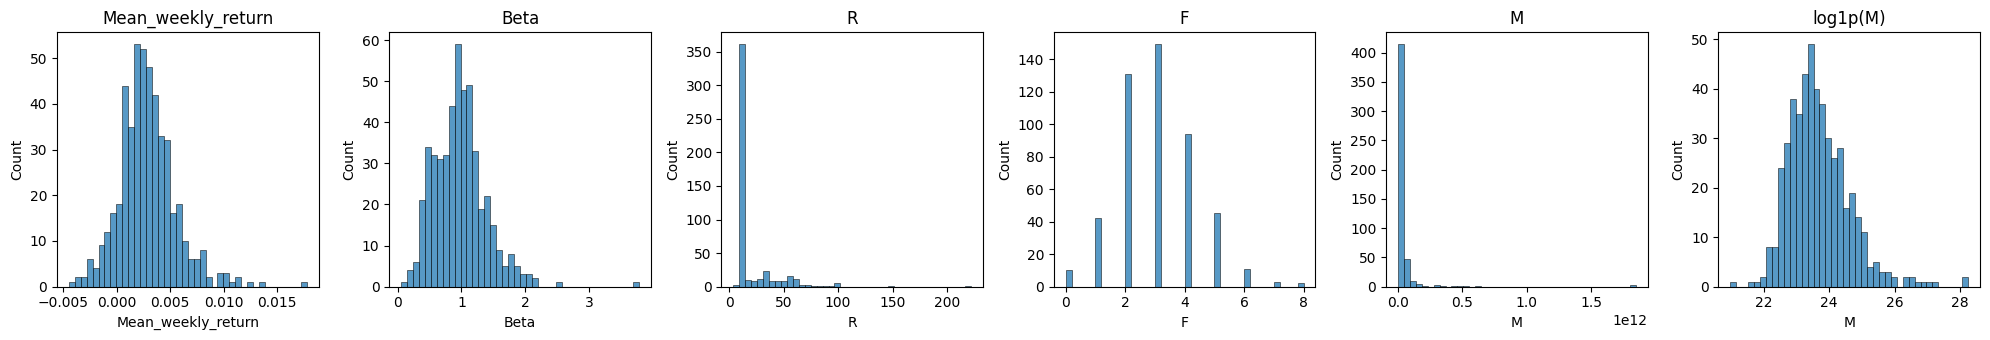

Standardised means ~0 and sds ~1:


,Mean_weekly_return,Beta,R,F,log1p_M
mean,-0.000,-0.000,0.000,-0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001


In [ ]:
X_rr  = features.loc[common, ["Mean_weekly_return", "Beta"]]
X_rfm = features.loc[common, ["R", "F", "M"]].copy()

skew = pd.DataFrame({"Skew_raw": features.loc[common, FEATS].skew()})
skew.loc["log1p(M)", "Skew_raw"] = np.log1p(X_rfm["M"]).skew()
zf = features.loc[common, FEATS].assign(**{"log1p(M)": np.log1p(features.loc[common, "M"])})
z = (zf - zf.mean()) / zf.std()
skew["Outliers_|z|>3"] = (z.abs() > 3).sum()
display(skew.round(3))

fig, axes = plt.subplots(1, 6, figsize=(20, 3.5))
for ax, col in zip(axes, FEATS):
    sns.histplot(features.loc[common, col], ax=ax, bins=40); ax.set_title(col)
sns.histplot(np.log1p(X_rfm["M"]), ax=axes[5], bins=40); axes[5].set_title("log1p(M)")
plt.tight_layout(); plt.savefig("outputs/feature_distributions.png", dpi=150); plt.show()

X_rfm["M"] = np.log1p(X_rfm["M"])
X_rfm = X_rfm.rename(columns={"M": "log1p_M"})

Z_rr  = pd.DataFrame(StandardScaler().fit_transform(X_rr),  index=common, columns=X_rr.columns)
Z_rfm = pd.DataFrame(StandardScaler().fit_transform(X_rfm), index=common, columns=X_rfm.columns)
print("Standardised means ~0 and sds ~1:")
pd.concat([Z_rr.agg(["mean", "std"]), Z_rfm.agg(["mean", "std"])], axis=1).round(3)

Tasks 2.2 and 2.3

In [ ]:
def scan_k(Z, method, ks=range(2, 9)):
    rows, labels = [], {}
    for k in ks:
        if method == "ward":
            lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z)
            inertia = np.nan
        else:
            km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Z)
            lab, inertia = km.labels_, km.inertia_
        sizes = np.bincount(lab)
        rows.append({"k": k, "Silhouette": silhouette_score(Z, lab), "Inertia": inertia,
                     "Smallest": sizes.min(), "Sizes": sorted(sizes.tolist(), reverse=True)})
        labels[k] = lab
    return pd.DataFrame(rows).set_index("k"), labels

def suggest_k(tbl, n, min_frac=0.03):
    ok = tbl[tbl["Smallest"] >= max(5, min_frac * n)]
    return int((ok if len(ok) else tbl)["Silhouette"].idxmax())

scans = {}
for name, Z in [("RR", Z_rr), ("RFM", Z_rfm)]:
    for method in ["ward", "kmeans"]:
        tbl, labs = scan_k(Z, method)
        scans[(name, method)] = (tbl, labs)
        tbl.to_csv(f"outputs/k_scan_{name}_{method}.csv")
        print(f"\n=== {name} – {method} (suggested k = {suggest_k(tbl, len(Z))}) ===")
        display(tbl.round(3))


=== RR – ward (suggested k = 2) ===


,Silhouette,Inertia,Smallest,Sizes
k,,,,
2,0.340,NaN,92,"[395, 92]"
3,0.273,NaN,92,"[231, 164, 92]"
4,0.282,NaN,48,"[183, 164, 92, 48]"
5,0.304,NaN,48,"[183, 98, 92, 66, 48]"
6,0.320,NaN,5,"[183, 98, 87, 66, 48, 5]"
7,0.324,NaN,5,"[161, 98, 87, 66, 48, 22, 5]"
8,0.321,NaN,5,"[161, 98, 66, 56, 48, 31, 22, 5]"



=== RR – kmeans (suggested k = 2) ===


,Silhouette,Inertia,Smallest,Sizes
k,,,,
2,0.387,623.163,143,"[344, 143]"
3,0.328,462.670,119,"[203, 165, 119]"
4,0.326,372.687,41,"[160, 154, 132, 41]"
5,0.340,310.540,27,"[170, 131, 109, 50, 27]"
6,0.335,265.774,5,"[157, 127, 105, 50, 43, 5]"
7,0.330,227.825,5,"[133, 97, 85, 79, 48, 40, 5]"
8,0.354,194.816,5,"[136, 80, 78, 76, 43, 40, 29, 5]"



=== RFM – ward (suggested k = 2) ===


,Silhouette,Inertia,Smallest,Sizes
k,,,,
2,0.369,NaN,86,"[401, 86]"
3,0.261,NaN,86,"[222, 179, 86]"
4,0.251,NaN,86,"[179, 136, 86, 86]"
5,0.270,NaN,10,"[179, 136, 86, 76, 10]"
6,0.291,NaN,10,"[161, 136, 86, 76, 18, 10]"
7,0.281,NaN,10,"[136, 90, 86, 76, 71, 18, 10]"
8,0.282,NaN,1,"[136, 90, 86, 76, 71, 18, 9, 1]"



=== RFM – kmeans (suggested k = 2) ===


,Silhouette,Inertia,Smallest,Sizes
k,,,,
2,0.423,1069.466,68,"[419, 68]"
3,0.325,799.250,63,"[273, 151, 63]"
4,0.341,611.186,61,"[213, 122, 91, 61]"
5,0.358,515.953,11,"[199, 122, 87, 68, 11]"
6,0.346,438.938,11,"[141, 119, 106, 70, 40, 11]"
7,0.347,387.677,1,"[140, 120, 108, 67, 40, 11, 1]"
8,0.349,343.524,1,"[140, 106, 81, 67, 64, 17, 11, 1]"


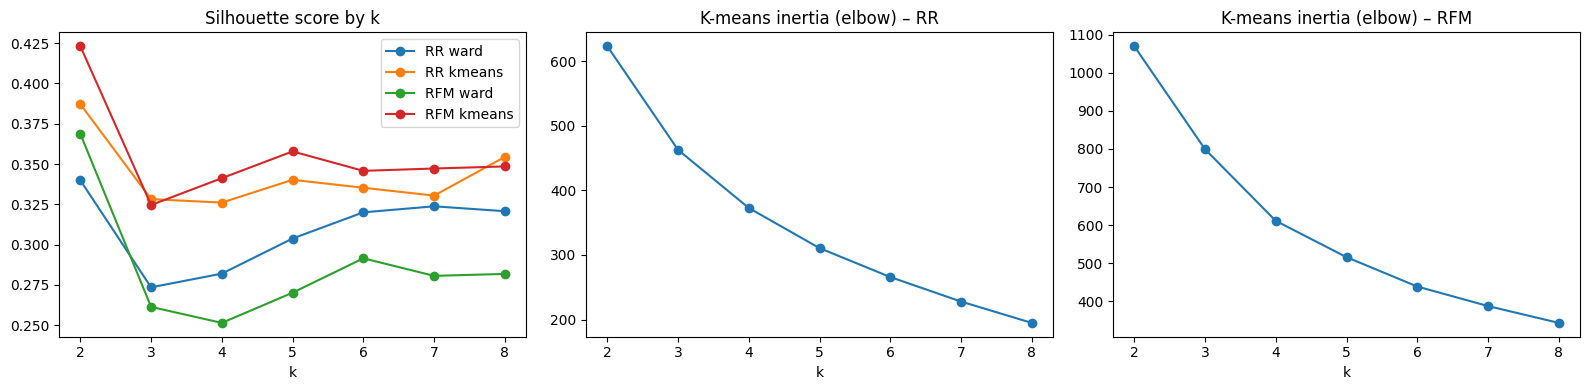

In [ ]:
# Silhouette (all) and inertia (K-means elbow) plots
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for (name, method), (tbl, _) in scans.items():
    axes[0].plot(tbl.index, tbl["Silhouette"], marker="o", label=f"{name} {method}")
for name in ["RR", "RFM"]:
    tbl = scans[(name, "kmeans")][0]
    axes[1 if name == "RR" else 2].plot(tbl.index, tbl["Inertia"], marker="o")
    axes[1 if name == "RR" else 2].set_title(f"K-means inertia (elbow) – {name}")
axes[0].set_title("Silhouette score by k"); axes[0].legend()
for ax in axes: ax.set_xlabel("k")
plt.tight_layout(); plt.savefig("outputs/k_selection_plots.png", dpi=150); plt.show()

In [ ]:
# Profiles behind the k choice (brief 2.2: silhouette, sizes and interpretable profiles)
pk = features.loc[common].assign(Mean_weekly_return_pct=lambda d: d["Mean_weekly_return"] * 100,
                                 M_bn_usd=lambda d: d["M"] / 1e9)
for name, cols in [("RR", ["Mean_weekly_return_pct", "Beta"]), ("RFM", ["R", "F", "M_bn_usd"])]:
    tbl, labs = scans[(name, "ward")]
    for k in sorted(tbl["Silhouette"].nlargest(3).index):
        p = pk.groupby(labs[k])[cols].median().round(2)
        p.insert(0, "n", pd.Series(labs[k]).value_counts().sort_index().values)
        print(f"{name} – Ward k = {k} (median, original units)")
        display(p)

RR – Ward k = 2 (median, original units)


,n,Mean_weekly_return_pct,Beta
0,395,0.21,0.88
1,92,0.55,1.22


RR – Ward k = 7 (median, original units)


,n,Mean_weekly_return_pct,Beta
0,87,0.53,1.21
1,48,0.25,1.51
2,161,0.18,0.94
3,98,0.39,0.67
4,66,0.11,0.45
5,5,1.26,2.00
6,22,-0.15,1.09


RR – Ward k = 8 (median, original units)


,n,Mean_weekly_return_pct,Beta
0,161,0.18,0.94
1,48,0.25,1.51
2,5,1.26,2.00
3,98,0.39,0.67
4,66,0.11,0.45
5,31,0.78,1.36
6,22,-0.15,1.09
7,56,0.47,1.20


... (2 outputs left out)

RFM – Ward k = 6 (median, original units)


,n,R,F,M_bn_usd
0,161,11.0,3.0,31.29
1,136,11.0,3.0,8.44
2,10,102.0,0.0,23.79
3,86,11.0,4.0,13.37
4,76,53.0,2.0,21.15
5,18,12.5,5.0,244.87


RFM – Ward k = 8 (median, original units)


,n,R,F,M_bn_usd
0,136,11.0,3.0,8.44
1,76,53.0,2.0,21.15
2,71,11.0,2.0,36.04
3,86,11.0,4.0,13.37
4,9,102.0,0.0,22.75
5,18,12.5,5.0,244.87
6,90,11.0,3.0,27.25
7,1,222.0,0.0,1825.34


In [ ]:
# >>> SET YOUR FINAL CHOICES HERE after reading the tables, dendrograms and profiles <<<
K = {(n, m): suggest_k(scans[(n, m)][0], len(common)) for (n, m) in scans}
# Example override:  K[("RFM", "ward")] = 4
K

{('RR', 'ward'): 2,
 ('RR', 'kmeans'): 2,
 ('RFM', 'ward'): 2,
 ('RFM', 'kmeans'): 2}

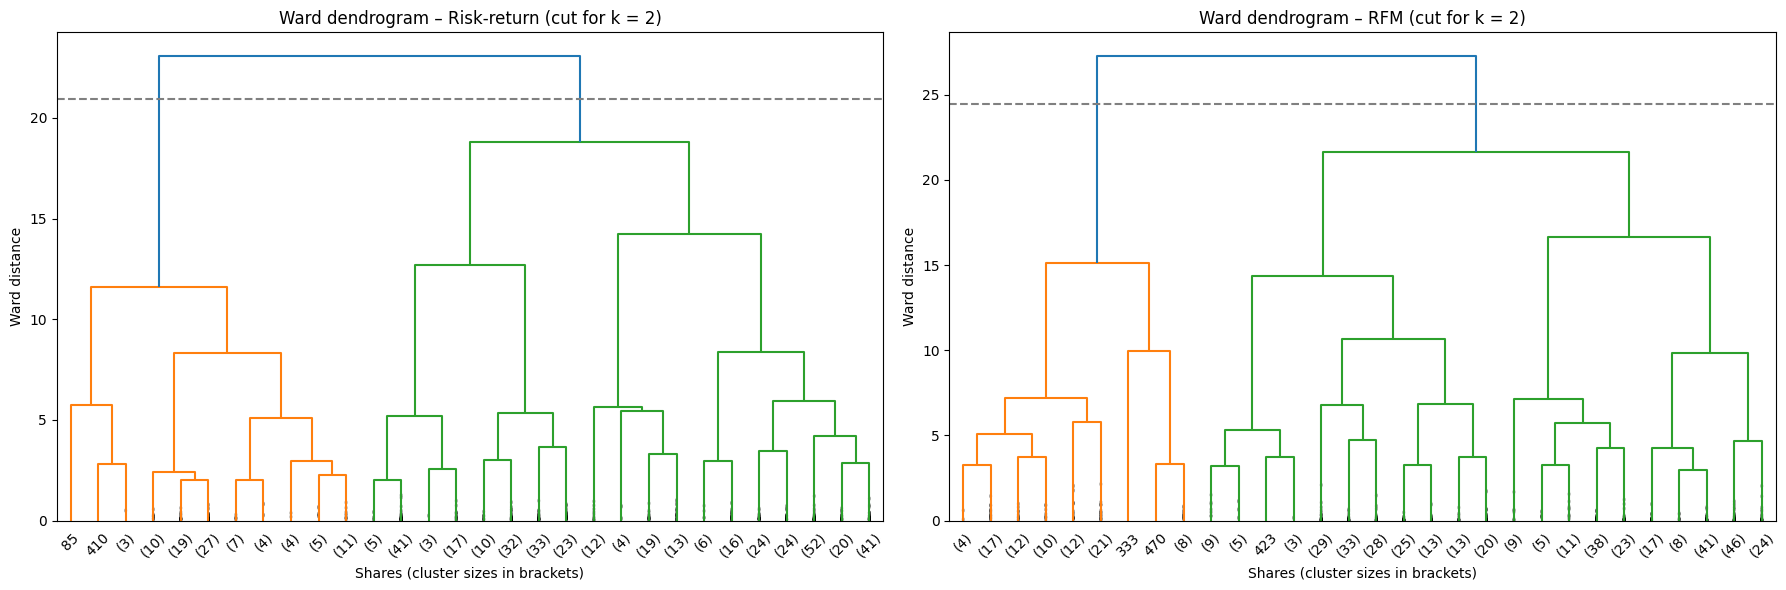

In [ ]:
# One dendrogram per feature matrix (Ward, Euclidean, standardised features)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, (name, Z) in zip(axes, [("Risk-return", Z_rr), ("RFM", Z_rfm)]):
    key = "RR" if name == "Risk-return" else "RFM"
    link = linkage(Z.values, method="ward", metric="euclidean")
    k = K[(key, "ward")]
    cut = (link[-k, 2] + link[-(k - 1), 2]) / 2                 # height giving k clusters
    dendrogram(link, truncate_mode="lastp", p=30, ax=ax, color_threshold=cut, show_contracted=True)
    ax.axhline(cut, ls="--", c="grey")
    ax.set_title(f"Ward dendrogram – {name} (cut for k = {k})")
    ax.set_xlabel("Shares (cluster sizes in brackets)"); ax.set_ylabel("Ward distance")
plt.tight_layout(); plt.savefig("outputs/dendrograms.png", dpi=150); plt.show()

In [ ]:
# Four baseline solutions
labels = pd.DataFrame(index=common)
labels["RR_Ward"]    = scans[("RR", "ward")][1][K[("RR", "ward")]]
labels["RR_KMeans"]  = scans[("RR", "kmeans")][1][K[("RR", "kmeans")]]
labels["RFM_Ward"]   = scans[("RFM", "ward")][1][K[("RFM", "ward")]]
labels["RFM_KMeans"] = scans[("RFM", "kmeans")][1][K[("RFM", "kmeans")]]
labels.to_csv("outputs/cluster_assignments.csv")
labels.apply(lambda s: s.value_counts().sort_index().tolist())

,RR_Ward,RR_KMeans,RFM_Ward,RFM_KMeans
0,395,143,401,419
1,92,344,86,68


Task 2.4

In [ ]:
orig = features.loc[common].assign(Mean_weekly_return_pct=lambda d: d["Mean_weekly_return"] * 100,
                                   M_bn_usd=lambda d: d["M"] / 1e9)

def profile(col, cols):
    p = orig.groupby(labels[col])[cols].agg(["mean", "median"]).round(3)
    p.insert(0, ("Shares", "n"), labels[col].value_counts().sort_index())
    return p

profiles = {}
for col, cols in [("RR_Ward", ["Mean_weekly_return_pct", "Beta"]), ("RR_KMeans", ["Mean_weekly_return_pct", "Beta"]),
                  ("RFM_Ward", ["R", "F", "M_bn_usd"]), ("RFM_KMeans", ["R", "F", "M_bn_usd"])]:
    profiles[col] = profile(col, cols)
    profiles[col].to_csv(f"outputs/profile_{col}.csv")
    print(f"\n=== {col} profile (original units) ==="); display(profiles[col])


=== RR_Ward profile (original units) ===


Shares Mean_weekly_return_pct          Beta       
             n                   mean median   mean median
RR_Ward                                                   
0          395                  0.205   0.21  0.898  0.882
1           92                  0.632   0.55  1.298  1.218


=== RR_KMeans profile (original units) ===


Shares Mean_weekly_return_pct          Beta       
               n                   mean median   mean median
RR_KMeans                                                   
0            143                  0.533  0.486  1.350  1.278
1            344                  0.183  0.192  0.817  0.837


=== RFM_Ward profile (original units) ===


Shares       R             F        M_bn_usd        
              n    mean median   mean median     mean  median
RFM_Ward                                                     
0           401  12.561   11.0  3.204    3.0   37.455  15.457
1            86  57.000   54.0  1.977    2.0   48.248  21.450


=== RFM_KMeans profile (original units) ===


Shares       R             F        M_bn_usd        
                n    mean median   mean median     mean  median
RFM_KMeans                                                     
0             419  13.442   11.0  3.184    3.0   32.657  15.657
1              68  63.338   55.0  1.779    2.0   80.671  22.250

PCA loadings (RFM):


,R,F,log1p_M
PC1,0.711,-0.650,0.268
PC2,0.023,0.402,0.915


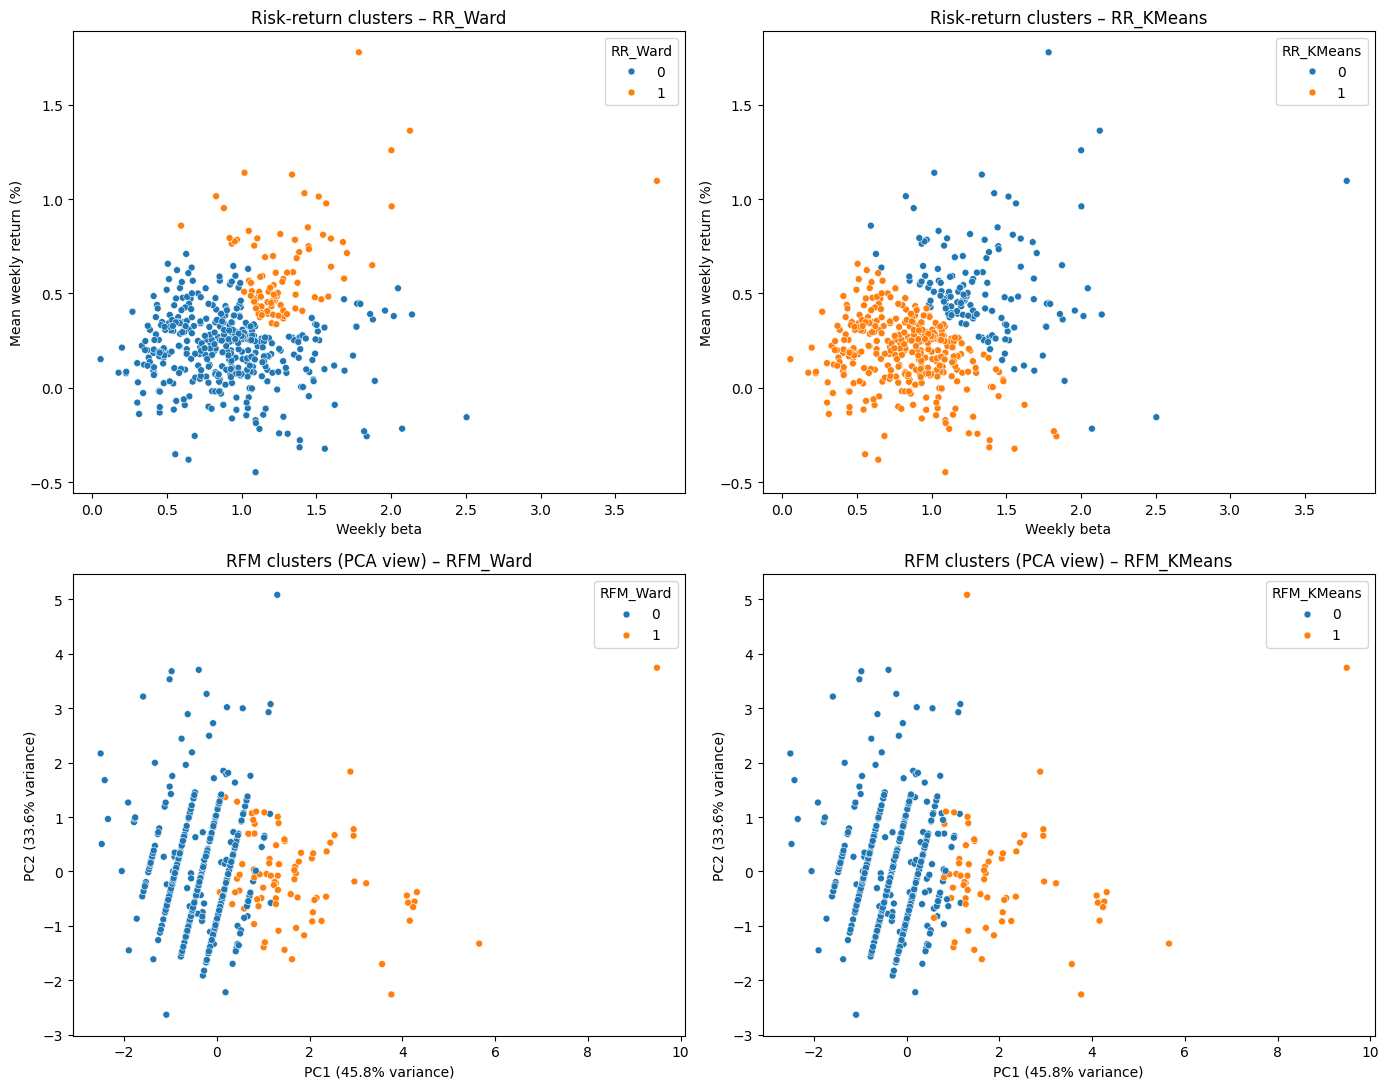


RR: Ward vs K-means adjusted Rand index = 0.598


K-means,0,1
Ward,,
0,51,344
1,92,0



RFM: Ward vs K-means adjusted Rand index = 0.779


K-means,0,1
Ward,,
0,399,2
1,20,66


In [ ]:
pca = PCA(n_components=2, random_state=SEED).fit(Z_rfm)
pcs = pca.transform(Z_rfm); ev = pca.explained_variance_ratio_ * 100
print("PCA loadings (RFM):"); display(pd.DataFrame(pca.components_, columns=Z_rfm.columns, index=["PC1", "PC2"]).round(3))

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, col in zip(axes[0], ["RR_Ward", "RR_KMeans"]):
    sns.scatterplot(x=orig["Beta"], y=orig["Mean_weekly_return_pct"], hue=labels[col], palette="tab10", ax=ax, s=25)
    ax.set_xlabel("Weekly beta"); ax.set_ylabel("Mean weekly return (%)"); ax.set_title(f"Risk-return clusters – {col}")
for ax, col in zip(axes[1], ["RFM_Ward", "RFM_KMeans"]):
    sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=labels[col], palette="tab10", ax=ax, s=25)
    ax.set_xlabel(f"PC1 ({ev[0]:.1f}% variance)"); ax.set_ylabel(f"PC2 ({ev[1]:.1f}% variance)")
    ax.set_title(f"RFM clusters (PCA view) – {col}")
plt.tight_layout(); plt.savefig("outputs/cluster_scatterplots.png", dpi=150); plt.show()

# Algorithm comparison on the same shares
for m in ["RR", "RFM"]:
    ari = adjusted_rand_score(labels[f"{m}_Ward"], labels[f"{m}_KMeans"])
    print(f"\n{m}: Ward vs K-means adjusted Rand index = {ari:.3f}")
    display(pd.crosstab(labels[f"{m}_Ward"], labels[f"{m}_KMeans"], rownames=["Ward"], colnames=["K-means"]))

Task 2.5

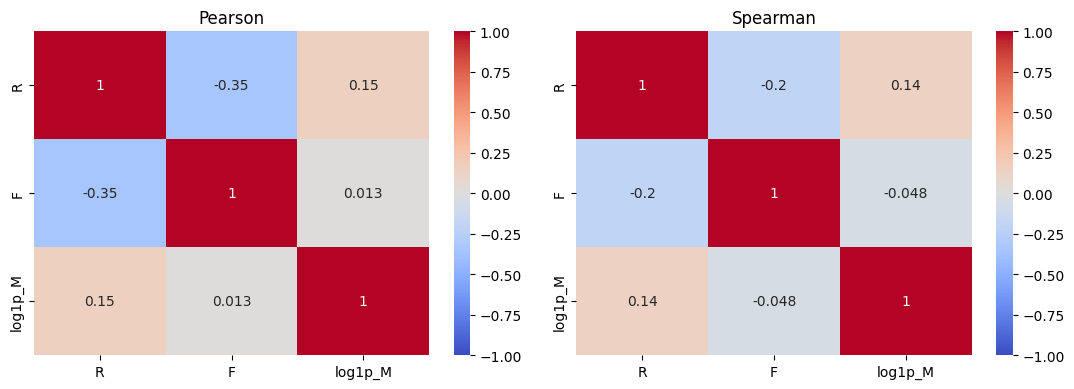

In [ ]:
corr_p = X_rfm.corr(method="pearson").round(3)
corr_s = X_rfm.corr(method="spearman").round(3)
corr_p.to_csv("outputs/rfm_correlation_pearson.csv"); corr_s.to_csv("outputs/rfm_correlation_spearman.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(corr_p, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0]); axes[0].set_title("Pearson")
sns.heatmap(corr_s, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1]); axes[1].set_title("Spearman")
plt.tight_layout(); plt.savefig("outputs/rfm_correlations.png", dpi=150); plt.show()

In [ ]:
k_rfm = K[("RFM", "ward")]
Z_rf = StandardScaler().fit_transform(X_rfm[["R", "F"]])       # standardise the reduced matrix afresh
labels["RF_only_Ward"] = AgglomerativeClustering(n_clusters=k_rfm, linkage="ward").fit_predict(Z_rf)

ari_rf = adjusted_rand_score(labels["RFM_Ward"], labels["RF_only_Ward"])
print(f"Ward RFM vs Ward R+F only (k = {k_rfm}): adjusted Rand index = {ari_rf:.3f}")
display(pd.crosstab(labels["RFM_Ward"], labels["RF_only_Ward"], rownames=["R,F,M"], colnames=["R,F only"]))

# Do clusters differ mainly in traded value (liquidity proxy)?
for col in ["RFM_Ward", "RF_only_Ward"]:
    p = orig.groupby(labels[col])[["R", "F", "M_bn_usd"]].median().round(2)
    p.insert(0, "n", labels[col].value_counts().sort_index())
    p.to_csv(f"outputs/traded_value_profile_{col}.csv")
    print(f"\n{col} – median profile"); display(p)

Ward RFM vs Ward R+F only (k = 2): adjusted Rand index = 0.922


"R,F only",0,1
"R,F,M",,
0,395,6
1,2,84



RFM_Ward – median profile


,n,R,F,M_bn_usd
RFM_Ward,,,,
0,401,11.0,3.0,15.46
1,86,54.0,2.0,21.45



RF_only_Ward – median profile


,n,R,F,M_bn_usd
RF_only_Ward,,,,
0,397,11.0,3.0,15.46
1,90,53.5,2.0,20.49


Task 3

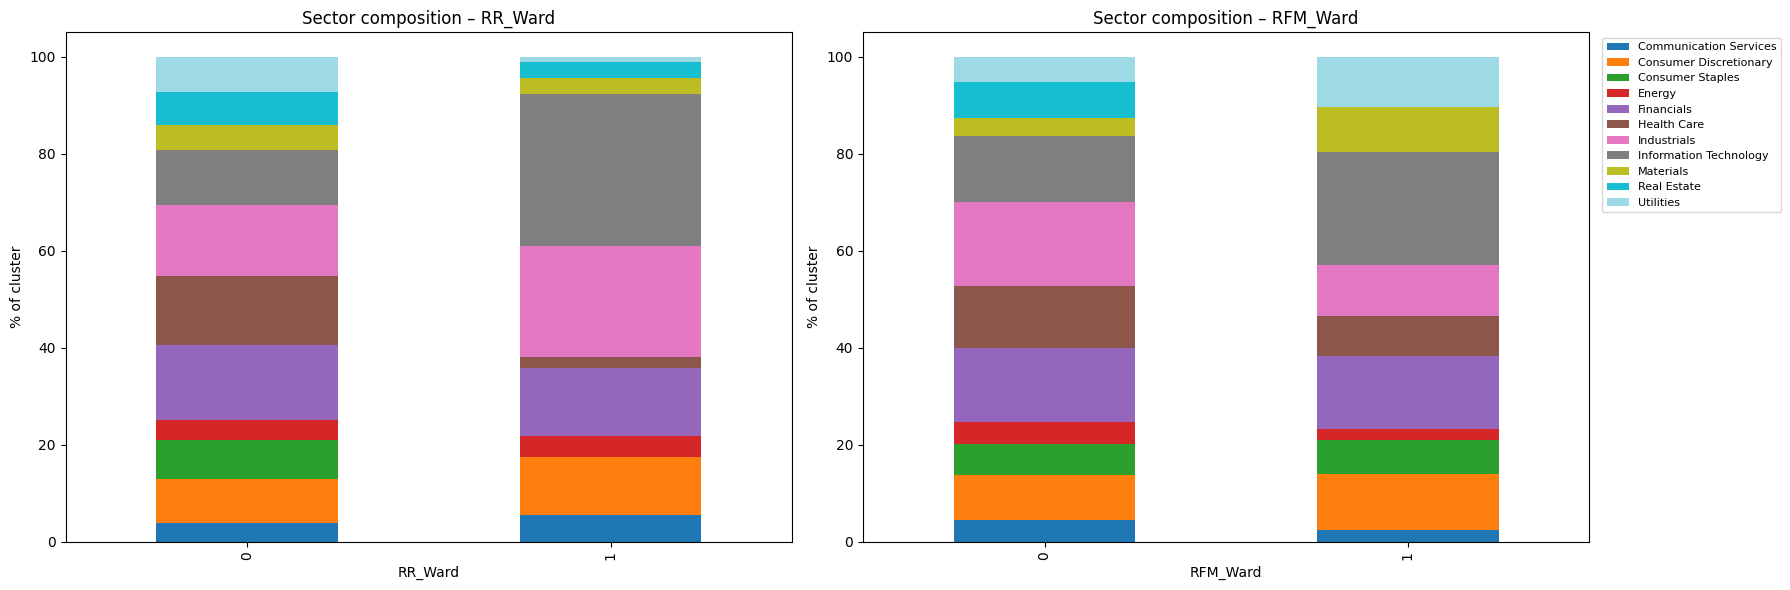

Risk-return vs RFM membership (Ward), ARI = 0.03


RFM,0,1
Risk-return,,
0,329,66
1,72,20


In [ ]:
sector = features.loc[common, "GICS Sector"]
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, col in zip(axes, ["RR_Ward", "RFM_Ward"]):
    comp = pd.crosstab(labels[col], sector, normalize="index") * 100
    comp.to_csv(f"outputs/sector_composition_{col}.csv")
    comp.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", legend=(col == "RFM_Ward"))
    ax.set_ylabel("% of cluster"); ax.set_title(f"Sector composition – {col}")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig("outputs/sector_composition.png", dpi=150); plt.show()

print("Risk-return vs RFM membership (Ward), ARI =",
      round(adjusted_rand_score(labels["RR_Ward"], labels["RFM_Ward"]), 3))
display(pd.crosstab(labels["RR_Ward"], labels["RFM_Ward"], rownames=["Risk-return"], colnames=["RFM"]))

In [ ]:
# Final feature table: one row per included share + all cluster assignments
final = features.loc[common, ["Security", "GICS Sector", "Mean_weekly_return", "Beta", "Aligned_weeks",
                              "Last_event", "R", "F", "M"]].join(labels)
final.to_csv("outputs/final_feature_table_with_clusters.csv")
json.dump({"observation_date": str(OBS_DATE.date()), "weeks": int(len(wk_ret)),
           "shares_extracted": len(tickers), "shares_retained": len(retained), "shares_clustered": len(common),
           "chosen_k": {f"{a}_{b}": v for (a, b), v in K.items()}, "seed": SEED, **versions},
          open("outputs/run_summary.json", "w"), indent=2)
print("Saved files:"); print(sorted(os.listdir("outputs")))
final.head()

Saved files:
['cluster_assignments.csv', 'cluster_scatterplots.png', 'dendrograms.png', 'feature_distributions.png', 'feature_summary.csv', 'feature_table.csv', 'final_feature_table_with_clusters.csv', 'high_volume_event_flags.csv.gz', 'inclusion_exclusion_log.csv', 'k_scan_RFM_kmeans.csv', 'k_scan_RFM_ward.csv', 'k_scan_RR_kmeans.csv', 'k_scan_RR_ward.csv', 'k_selection_plots.png', 'package_versions.json', 'profile_RFM_KMeans.csv', 'profile_RFM_Ward.csv', 'profile_RR_KMeans.csv', 'profile_RR_Ward.csv', 'rfm_correlation_pearson.csv', 'rfm_correlation_spearman.csv', 'rfm_correlations.png', 'run_summary.json', 'sector_composition.png', 'sector_composition_RFM_Ward.csv', 'sector_composition_RR_Ward.csv', 'split_events.csv', 'traded_value_profile_RFM_Ward.csv', 'traded_value_profile_RF_only_Ward.csv', 'validation_log.csv', 'weekly_returns.csv', 'worked_example_AAPL.csv']


,Security,GICS Sector,Mean_weekly_return,Beta,Aligned_weeks,Last_event,R,F,M,RR_Ward,RR_KMeans,RFM_Ward,RFM_KMeans,RF_only_Ward
Ticker,,,,,,,,,,,,,,
MMM,3M,Industrials,0.001142,0.869079,207,2024-12-20,11,4.0,2.599146e+10,0,1,0,0,0
AOS,A. O. Smith,Industrials,0.001991,1.042805,207,2024-12-20,11,2.0,4.748980e+09,0,1,0,0,0
ABT,Abbott Laboratories,Health Care,0.000971,0.583543,207,2024-12-20,11,1.0,3.523027e+10,0,1,0,0,0
ABBV,AbbVie,Health Care,0.003749,0.425366,207,2024-12-20,11,3.0,6.837054e+10,0,1,0,0,0
ACN,Accenture,Information Technology,0.002376,1.143300,207,2024-12-20,11,2.0,5.199430e+10,0,1,0,0,0


In [ ]:
# Independent checks against the worked examples in the brief and the Week 3 lecture
v = pd.Series([1e6] * 20 + [2.5e6, 1.8e6, 2e6], index=pd.bdate_range("2024-01-01", periods=23))
b = v.shift(1).rolling(20, min_periods=20).mean()
e = (v > 2 * b) & b.notna()
assert 2 * b.iloc[20] == 2e6 and e.iloc[20] and not e.iloc[21] and not e.iloc[22]
print("1.4.2  baseline 1m -> threshold 2m; 2.5m qualifies, 1.8m and exactly 2.0m do not")

assert (pd.Timestamp("2024-09-20") - pd.Timestamp("2024-09-15")).days == 5
print("1.4.1  observation 20 Sep, event 15 Sep -> R = 5 calendar days")

assert 100 * 2e6 == 2e8
print("1.4.3  close $100 x volume 2m = $200m traded value")

p = pd.Series([100, 105, 99.75], index=pd.to_datetime(["2024-01-05", "2024-01-12", "2024-01-19"]))
assert np.isclose(p.pct_change(fill_method=None).iloc[2], -0.05)
print("1.3.1  weekly return 99.75 / 105 - 1 = -0.05")

mm, ss = pd.Series([-.02, 0, .02]), pd.Series([-.04, 0, .04])
assert np.isclose(mm.var(), 0.0004) and np.isclose(ss.cov(mm), 0.0008) and np.isclose(ss.cov(mm) / mm.var(), 2.0)
print("1.3.2  Week 3 lecture: market -2/0/+2%, share -4/0/+4% -> var 0.0004, cov 0.0008, beta 2.00")

assert wk_ret.index.equals(mkt_ret.index) and not wk_ret.index.has_duplicates
assert OBS_DATE == min(adj_c[retained].apply(lambda s: s.last_valid_index()).min(), cal.max())
assert rfm.loc[rfm["R"].notna(), "R"].min() >= 0 and rfm["F"].dropna().between(0, 60).all()
print("checks on this run: week labels aligned, observation date is the common completed date, R and F in range")

1.4.2  baseline 1m -> threshold 2m; 2.5m qualifies, 1.8m and exactly 2.0m do not
1.4.1  observation 20 Sep, event 15 Sep -> R = 5 calendar days
1.4.3  close $100 x volume 2m = $200m traded value
1.3.1  weekly return 99.75 / 105 - 1 = -0.05
1.3.2  Week 3 lecture: market -2/0/+2%, share -4/0/+4% -> var 0.0004, cov 0.0008, beta 2.00
checks on this run: week labels aligned, observation date is the common completed date, R and F in range


In [ ]:
# Download everything to upload to GitHub (Colab only)
!zip -qr cwk1_outputs.zip data outputs
from google.colab import files
files.download("cwk1_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>